# Submission 02

In this submission, I kept the same 34 features and preprocessing from Submission 01 and experimented with a few small improvements. Tuning Logistic Regression had very little impact, but increasing the minimum leaf size in Random Forest improved its ROC-AUC from 0.7037 to 0.7251. I also tested missing-value indicators, which slightly improved the best Logistic Regression score from 0.7363 to 0.7380.

The overall improvement is small, but these experiments helped me understand which changes were useful and which had limited impact.

## Import Libraries

In [1]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
SEED = 42

## Load Dataset

In [3]:
paths = ['/kaggle/input/competitions/machine-learning-fall-26-challenge-1-iba-karachi/',
         '/kaggle/input/machine-learning-fall-26-challenge-1-iba-karachi/',
         './']
D = next(p for p in paths if os.path.exists(p + 'train.csv'))

train = pd.read_csv(D + 'train.csv')
test = pd.read_csv(D + 'test.csv')
encounters = pd.read_csv(D + 'index_encounters.csv')
patients = pd.read_csv(D + 'patients.csv')
hospitals = pd.read_csv(D + 'hospitals.csv')
diagnoses = pd.read_csv(D + 'diagnoses.csv')
procedures = pd.read_csv(D + 'procedures.csv')
labs = pd.read_csv(D + 'lab_results.csv')
vitals = pd.read_csv(D + 'vitals.csv')
meds = pd.read_csv(D + 'medications.csv')
transfers = pd.read_csv(D + 'unit_transfers.csv')
prior = pd.read_csv(D + 'prior_utilization.csv')
planning = pd.read_csv(D + 'discharge_planning.csv')

## Data Cleaning

In [4]:
patients['insurance_type'] = patients.insurance_type.str.upper()
patients['race_ethnicity'] = patients.race_ethnicity.replace({'?': 'Unknown'})
patients.loc[patients.birth_year <= 1900, 'birth_year'] = np.nan

encounters['admit_dt'] = pd.to_datetime(encounters.admit_dt)
encounters['discharge_dt'] = pd.to_datetime(encounters.discharge_dt)

planning['home_health_referral'] = (planning.home_health_referral == 'Y').astype(int)
planning['education_done'] = planning.education_done.map({'Yes': 1, 'No': 0})

## Feature Construction

In [5]:
df = (encounters
      .merge(patients, on='patient_id', how='left')
      .merge(hospitals, on='hospital_id', how='left')
      .merge(planning, on='encounter_id', how='left'))

df['age'] = df.admit_dt.dt.year - df.birth_year
df['los_days'] = (df.discharge_dt - df.admit_dt).dt.total_seconds() / 86400

counts = {
    'n_diagnoses': diagnoses.groupby('encounter_id').size(),
    'n_procedures': procedures.groupby('encounter_id').size(),
    'n_labs': labs.groupby('encounter_id').size(),
    'n_labs_abnormal': labs[labs.abnormal_flag.isin(['H', 'L'])].groupby('encounter_id').size(),
    'n_vitals': vitals.groupby('encounter_id').size(),
    'n_medications': meds.groupby('encounter_id').size(),
    'n_meds_at_discharge': meds[meds.continued_at_discharge == 1].groupby('encounter_id').size(),
    'n_unit_transfers': transfers.groupby('encounter_id').size(),
    'n_icu_stays': transfers[transfers.unit == 'ICU'].groupby('encounter_id').size(),
}
for name, s in counts.items():
    df[name] = df.encounter_id.map(s).fillna(0)

prior_counts = pd.crosstab(prior.patient_id, prior.visit_type).add_prefix('prior_')
df = df.merge(prior_counts, left_on='patient_id', right_index=True, how='left')
df[prior_counts.columns] = df[prior_counts.columns].fillna(0)

df.shape

(109787, 42)

In [6]:
num_cols = ['age', 'los_days', 'deprivation_index', 'bed_size', 'teaching_flag',
            'n_diagnoses', 'n_procedures', 'n_labs', 'n_labs_abnormal', 'n_vitals',
            'n_medications', 'n_meds_at_discharge', 'n_unit_transfers', 'n_icu_stays',
            'prior_ED', 'prior_IP', 'prior_OP',
            'followup_scheduled_days', 'home_health_referral', 'med_reconciliation_done', 'education_done']
cat_cols = ['hospital_id', 'admission_type', 'admission_source', 'service_line', 'discharge_disposition',
            'attending_specialty', 'sex', 'race_ethnicity', 'language', 'marital_status',
            'insurance_type', 'urban_rural', 'ownership']

X = train[['encounter_id']].merge(df, on='encounter_id', how='left')
y = train.readmit_30d
X_test = test[['encounter_id']].merge(df, on='encounter_id', how='left')

print(X.shape, X_test.shape, len(num_cols) + len(cat_cols), 'features')

(76975, 42) (32812, 42) 34 features


## Preprocessing

In [7]:
numeric = Pipeline([('impute', SimpleImputer(strategy='median')),
                    ('scale', StandardScaler())])
categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
                        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
preprocess = ColumnTransformer([('num', numeric, num_cols),
                                ('cat', categorical, cat_cols)])

## Evaluation Function

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def evaluate(model, prep=preprocess):
    pipe = Pipeline([('prep', prep), ('model', clone(model))])
    pred = np.zeros(len(X))
    scores = {'ROC-AUC': [], 'Accuracy': [], 'Precision': [], 'Recall': [], 'F1': []}
    for tr_idx, va_idx in cv.split(X, y):
        pipe.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        p = pipe.predict_proba(X.iloc[va_idx])[:, 1]
        pred[va_idx] = p
        y_va, label = y.iloc[va_idx], p >= 0.5
        scores['ROC-AUC'].append(roc_auc_score(y_va, p))
        scores['Accuracy'].append(accuracy_score(y_va, label))
        scores['Precision'].append(precision_score(y_va, label, zero_division=0))
        scores['Recall'].append(recall_score(y_va, label))
        scores['F1'].append(f1_score(y_va, label))
    row = {k: np.mean(v) for k, v in scores.items()}
    row['Std'] = np.std(scores['ROC-AUC'])
    row['Folds'] = np.round(scores['ROC-AUC'], 4)
    return row, pred

## Submission 01 RUC Scores

Purpose of adding this is to show a difference between submission 1 and submission2 

In [9]:
sub01 = pd.DataFrame({'Model': ['Logistic Regression', 'Random Forest', 'Naive Bayes', 'KNN', 'Decision Tree'],
                      'Sub 01 ROC-AUC': [0.7363, 0.7037, 0.6798, 0.5980, 0.5465]})
sub01

,Model,Sub 01 ROC-AUC
0,Logistic Regression,0.7363
1,Random Forest,0.7037
2,Naive Bayes,0.6798
3,KNN,0.5980
4,Decision Tree,0.5465


## Experiment 1 Logistic Regression C

In [10]:
lr_rows, oof = [], {}
for C in [0.01, 0.1, 0.5, 1.0, 2.0]:
    row, pred = evaluate(LogisticRegression(C=C, max_iter=1000))
    lr_rows.append({'C': C, **row})
    oof[f'LR C={C}'] = pred
    print(f"C={C:<5} ROC-AUC {row['ROC-AUC']:.4f} ± {row['Std']:.4f}")

lr_results = pd.DataFrame(lr_rows)
lr_results.drop(columns='Folds').round(4)

C=0.01  ROC-AUC 0.7361 ± 0.0076
C=0.1   ROC-AUC 0.7366 ± 0.0079
C=0.5   ROC-AUC 0.7364 ± 0.0080
C=1.0   ROC-AUC 0.7363 ± 0.0080
C=2.0   ROC-AUC 0.7362 ± 0.0080


,C,ROC-AUC,Accuracy,Precision,Recall,F1,Std
0,0.01,0.7361,0.9014,0.6212,0.0551,0.1011,0.0076
1,0.10,0.7366,0.9015,0.6162,0.0597,0.1088,0.0079
2,0.50,0.7364,0.9016,0.6194,0.0605,0.1101,0.0080
3,1.00,0.7363,0.9016,0.6140,0.0610,0.1109,0.0080
4,2.00,0.7362,0.9015,0.6104,0.0605,0.1100,0.0080


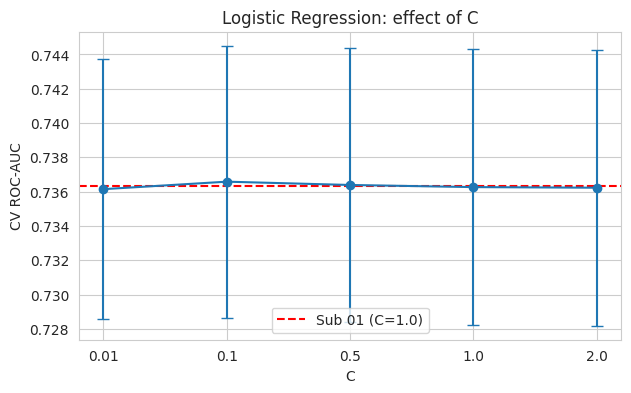

In [11]:
plt.figure(figsize=(7, 4))
plt.errorbar(lr_results.C.astype(str), lr_results['ROC-AUC'], yerr=lr_results.Std, marker='o', capsize=4)
plt.axhline(0.7363, color='red', linestyle='--', label='Sub 01 (C=1.0)')
plt.xlabel('C')
plt.ylabel('CV ROC-AUC')
plt.title('Logistic Regression: effect of C')
plt.legend()
plt.show()

## Experiment 2 Random Forest min_samples_leaf

In [12]:
rf_rows = []
for leaf in [1, 10, 50]:
    row, pred = evaluate(RandomForestClassifier(min_samples_leaf=leaf, n_jobs=-1, random_state=SEED))
    rf_rows.append({'min_samples_leaf': leaf, **row})
    oof[f'RF leaf={leaf}'] = pred
    print(f"min_samples_leaf={leaf:<3} ROC-AUC {row['ROC-AUC']:.4f} ± {row['Std']:.4f}")

rf_results = pd.DataFrame(rf_rows)
rf_results.drop(columns='Folds').round(4)

min_samples_leaf=1   ROC-AUC 0.7037 ± 0.0052
min_samples_leaf=10  ROC-AUC 0.7224 ± 0.0059
min_samples_leaf=50  ROC-AUC 0.7251 ± 0.0061


,min_samples_leaf,ROC-AUC,Accuracy,Precision,Recall,F1,Std
0,1,0.7037,0.9006,0.6621,0.0272,0.0523,0.0052
1,10,0.7224,0.9000,0.7561,0.0103,0.0203,0.0059
2,50,0.7251,0.8993,0.3333,0.0004,0.0008,0.0061


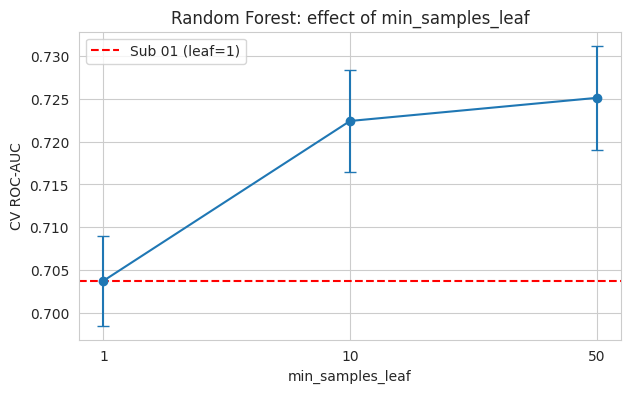

In [13]:
plt.figure(figsize=(7, 4))
plt.errorbar(rf_results.min_samples_leaf.astype(str), rf_results['ROC-AUC'], yerr=rf_results.Std, marker='o', capsize=4)
plt.axhline(0.7037, color='red', linestyle='--', label='Sub 01 (leaf=1)')
plt.xlabel('min_samples_leaf')
plt.ylabel('CV ROC-AUC')
plt.title('Random Forest: effect of min_samples_leaf')
plt.legend()
plt.show()

## Unchanged Baselines

For this submission I did'nt make any chnage in these models. It is same as submission 1

In [14]:
other_rows = []
for name, model in {'Naive Bayes': GaussianNB(),
                    'KNN': KNeighborsClassifier(),
                    'Decision Tree': DecisionTreeClassifier(random_state=SEED)}.items():
    row, pred = evaluate(model)
    other_rows.append({'Model': name, 'Setting': 'default', **row})
    oof[name] = pred

pd.DataFrame(other_rows).drop(columns='Folds').round(4)

,Model,Setting,ROC-AUC,Accuracy,Precision,Recall,F1,Std
0,Naive Bayes,default,0.6798,0.6497,0.1672,0.6218,0.2635,0.0056
1,KNN,default,0.5980,0.8944,0.3629,0.0641,0.1089,0.0041
2,Decision Tree,default,0.5465,0.8250,0.1746,0.1977,0.1854,0.0053


## Experiment 3 Missing Value Indicators

In [15]:
X[num_cols].isna().mean().loc[lambda s: s > 0].sort_values(ascending=False).round(3)

followup_scheduled_days    0.484
education_done             0.181
med_reconciliation_done    0.156
home_health_referral       0.112
bed_size                   0.084
deprivation_index          0.047
age                        0.002
dtype: float64

In [16]:
numeric_ind = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                        ('scale', StandardScaler())])
preprocess_ind = ColumnTransformer([('num', numeric_ind, num_cols),
                                    ('cat', categorical, cat_cols)])

best_lr = lr_results.loc[lr_results['ROC-AUC'].idxmax()]
best_rf = rf_results.loc[rf_results['ROC-AUC'].idxmax()]
lr_model = LogisticRegression(C=best_lr.C, max_iter=1000)
rf_model = RandomForestClassifier(min_samples_leaf=int(best_rf.min_samples_leaf), n_jobs=-1, random_state=SEED)

lr_ind, oof['LR + indicators'] = evaluate(lr_model, preprocess_ind)
rf_ind, oof['RF + indicators'] = evaluate(rf_model, preprocess_ind)

ind_results = pd.DataFrame([
    {'Model': f'Logistic Regression (C={best_lr.C})', 'Imputation': 'median', **best_lr.drop('C').to_dict()},
    {'Model': f'Logistic Regression (C={best_lr.C})', 'Imputation': 'median + indicator', **lr_ind},
    {'Model': f'Random Forest (leaf={int(best_rf.min_samples_leaf)})', 'Imputation': 'median', **best_rf.drop('min_samples_leaf').to_dict()},
    {'Model': f'Random Forest (leaf={int(best_rf.min_samples_leaf)})', 'Imputation': 'median + indicator', **rf_ind},
])
ind_results.drop(columns='Folds').round(4)

,Model,Imputation,ROC-AUC,Accuracy,Precision,Recall,F1,Std
0,Logistic Regression (C=0.1),median,0.7366,0.9015,0.6162,0.0597,0.1088,0.0079
1,Logistic Regression (C=0.1),median + indicator,0.7380,0.9016,0.6185,0.0615,0.1118,0.0077
2,Random Forest (leaf=50),median,0.7251,0.8993,0.3333,0.0004,0.0008,0.0061
3,Random Forest (leaf=50),median + indicator,0.7259,0.8993,0.3500,0.0005,0.0010,0.0050


In [17]:
pd.DataFrame({'Fold': range(1, 6),
              'LR median': best_lr.Folds,
              'LR median + indicator': lr_ind['Folds'],
              'Difference': np.round(lr_ind['Folds'] - best_lr.Folds, 4)})

,Fold,LR median,LR median + indicator,Difference
0,1,0.7370,0.7374,0.0004
1,2,0.7445,0.7479,0.0034
2,3,0.7340,0.7355,0.0015
3,4,0.7444,0.7438,-0.0006
4,5,0.7230,0.7255,0.0025


## Results Comparison

In [18]:
summary = pd.DataFrame([
    {'Model': 'Logistic Regression', 'Setting': f'C={best_lr.C}, missing indicators', **lr_ind},
    {'Model': 'Random Forest', 'Setting': f'min_samples_leaf={int(best_rf.min_samples_leaf)}, missing indicators', **rf_ind},
    *other_rows,
]).merge(sub01, on='Model')
summary['Change'] = summary['ROC-AUC'] - summary['Sub 01 ROC-AUC']
summary = summary.sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
summary[['Model', 'Setting', 'Sub 01 ROC-AUC', 'ROC-AUC', 'Change', 'Std', 'Accuracy', 'Precision', 'Recall', 'F1']].round(4)

,Model,Setting,Sub 01 ROC-AUC,ROC-AUC,Change,Std,Accuracy,Precision,Recall,F1
0,Logistic Regression,"C=0.1, missing indicators",0.7363,0.7380,0.0017,0.0077,0.9016,0.6185,0.0615,0.1118
1,Random Forest,"min_samples_leaf=50, missing indicators",0.7037,0.7259,0.0222,0.0050,0.8993,0.3500,0.0005,0.0010
2,Naive Bayes,default,0.6798,0.6798,0.0000,0.0056,0.6497,0.1672,0.6218,0.2635
3,KNN,default,0.5980,0.5980,0.0000,0.0041,0.8944,0.3629,0.0641,0.1089
4,Decision Tree,default,0.5465,0.5465,-0.0000,0.0053,0.8250,0.1746,0.1977,0.1854


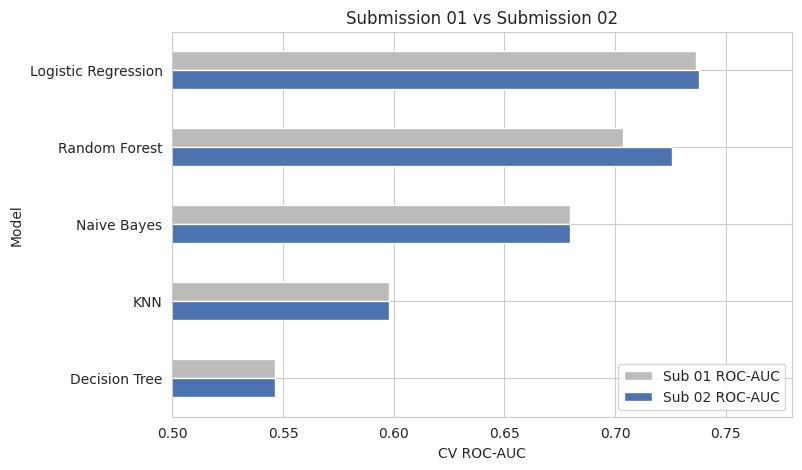

In [19]:
plot = summary.set_index('Model')[['Sub 01 ROC-AUC', 'ROC-AUC']].rename(columns={'ROC-AUC': 'Sub 02 ROC-AUC'})
plot.plot.barh(figsize=(8, 5), color=['#BBBBBB', '#4C72B0'])
plt.xlim(0.5, 0.78)
plt.xlabel('CV ROC-AUC')
plt.title('Submission 01 vs Submission 02')
plt.gca().invert_yaxis()
plt.show()

## ROC Curves

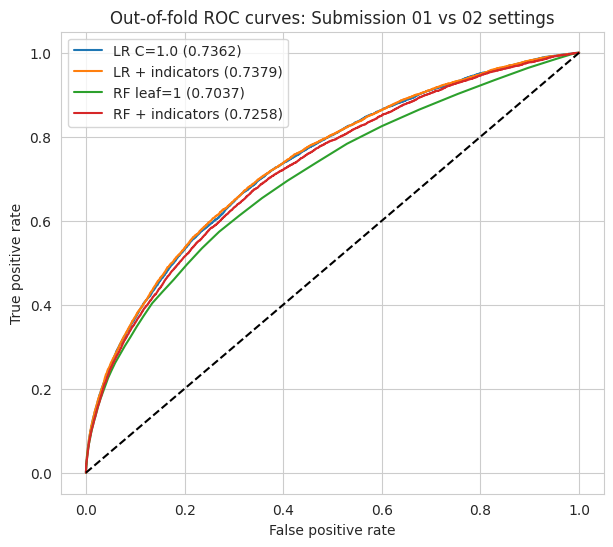

In [20]:
plt.figure(figsize=(7, 6))
for name in ['LR C=1.0', 'LR + indicators', 'RF leaf=1', 'RF + indicators']:
    fpr, tpr, _ = roc_curve(y, oof[name])
    plt.plot(fpr, tpr, label=f'{name} ({roc_auc_score(y, oof[name]):.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Out-of-fold ROC curves: Submission 01 vs 02 settings')
plt.legend()
plt.show()

## Final Model

In [21]:
candidates = {
    f'Logistic Regression (C={best_lr.C})': (lr_model, preprocess, best_lr['ROC-AUC']),
    f'Logistic Regression (C={best_lr.C}) + missing indicators': (lr_model, preprocess_ind, lr_ind['ROC-AUC']),
    f'Random Forest (leaf={int(best_rf.min_samples_leaf)})': (rf_model, preprocess, best_rf['ROC-AUC']),
    f'Random Forest (leaf={int(best_rf.min_samples_leaf)}) + missing indicators': (rf_model, preprocess_ind, rf_ind['ROC-AUC']),
}
best_name = max(candidates, key=lambda k: candidates[k][2])
model, prep, score = candidates[best_name]

final = Pipeline([('prep', prep), ('model', clone(model))])
final.fit(X, y)
print('Selected model:', best_name, f'(CV ROC-AUC {score:.4f})')

Selected model: Logistic Regression (C=0.1) + missing indicators (CV ROC-AUC 0.7380)


## Submission File

In [22]:
submission = pd.DataFrame({'encounter_id': X_test.encounter_id,
                           'readmit_30d': final.predict_proba(X_test)[:, 1]})
submission.to_csv('submission.csv', index=False)
print(submission.shape)
submission.head()

(32812, 2)


,encounter_id,readmit_30d
0,E14322700,0.076290
1,E10891017,0.063044
2,E15846764,0.142428
3,E35399048,0.142488
4,E18403456,0.032549
